In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import (
    carregar_noaa_por_tipo,
    identificar_porcoes_ativas,
    processar_ou_carregar_porcao,
    media_por_sink_raio,
    ajustar_lei_potencia,
    plotar_lei_potencia,
)

tipos_noaa = carregar_noaa_por_tipo()
for nome, df_t in tipos_noaa.items():
    print(f"{nome:16s}: {len(df_t):5d} pontos")

Ocean water     : 14363 pontos
Ocean sediment  :   319 pontos
Nurdle Patrol   : 10615 pontos
Beach           :   893 pontos


In [2]:
# 1. Rodar GebcoCutter + IPBA + CCA por porcao de terra e juntar as bacias globais
info, arr, label, porcoes_ativas = identificar_porcoes_ativas(tipos_noaa["Ocean water"], max_r_km=50.0)

bacias_por_porcao = [processar_ou_carregar_porcao(v, info, arr, label) for v in porcoes_ativas]
df_bacias_globais = pd.concat([d for d in bacias_por_porcao if len(d) > 0], ignore_index=True)
df_bacias_principais = df_bacias_globais[df_bacias_globais["area_km2"] >= 100.0].reset_index(drop=True)
print(f"Porcoes ativas: {len(porcoes_ativas)} | Bacias >= 100 km2: {len(df_bacias_principais)}")

Porcoes ativas: 1061 | Bacias >= 100 km2: 20168


In [3]:
# 2. Para cada tipo de lixo da NOAA, juntar apenas as bacias com valor no sink (R = 22 km e melhor R em 1..22 km)
resumo = []
pareados_r22 = {}

for nome, pts_df in tipos_noaa.items():
    df_22 = media_por_sink_raio(df_bacias_principais, pts_df, r_km=22.0)
    pareados_r22[nome] = df_22
    c_urb = ajustar_lei_potencia(df_22, "urban_population", "mp_mean")
    f_urb = ajustar_lei_potencia(df_22, "urban_population", "flux")
    f_tot = ajustar_lei_potencia(df_22, "total_population", "flux")
    resumo.append({
        "Tipo_NOAA": nome,
        "N_urb_22km": c_urb["N"],
        "beta_Conc_Urb": c_urb["beta"],
        "R2_Conc_Urb_pct": c_urb["r2_pct"],
        "p_Conc_Urb": c_urb["p_value"],
        "beta_Fluxo_Urb": f_urb["beta"],
        "R2_Fluxo_Urb_pct": f_urb["r2_pct"],
        "N_tot_22km": f_tot["N"],
        "beta_Fluxo_Tot": f_tot["beta"],
        "R2_Fluxo_Tot_pct": f_tot["r2_pct"],
        "p_Fluxo_Tot": f_tot["p_value"],
    })

df_resumo_tipos = pd.DataFrame(resumo)
print(df_resumo_tipos.round(3).to_string(index=False))

     Tipo_NOAA  N_urb_22km  beta_Conc_Urb  R2_Conc_Urb_pct  p_Conc_Urb  beta_Fluxo_Urb  R2_Fluxo_Urb_pct  N_tot_22km  beta_Fluxo_Tot  R2_Fluxo_Tot_pct  p_Fluxo_Tot
   Ocean water         314          0.372            7.931       0.000           0.607            17.049         624           0.525            25.270          0.0
Ocean sediment          44          0.292           19.633       0.003           0.611            37.216          80           0.765            54.008          0.0
 Nurdle Patrol         195          0.136            2.506       0.027           0.388             9.526         597           0.287            10.563          0.0
         Beach          76          0.194            2.990       0.135           0.462            13.096         240           0.400            15.614          0.0


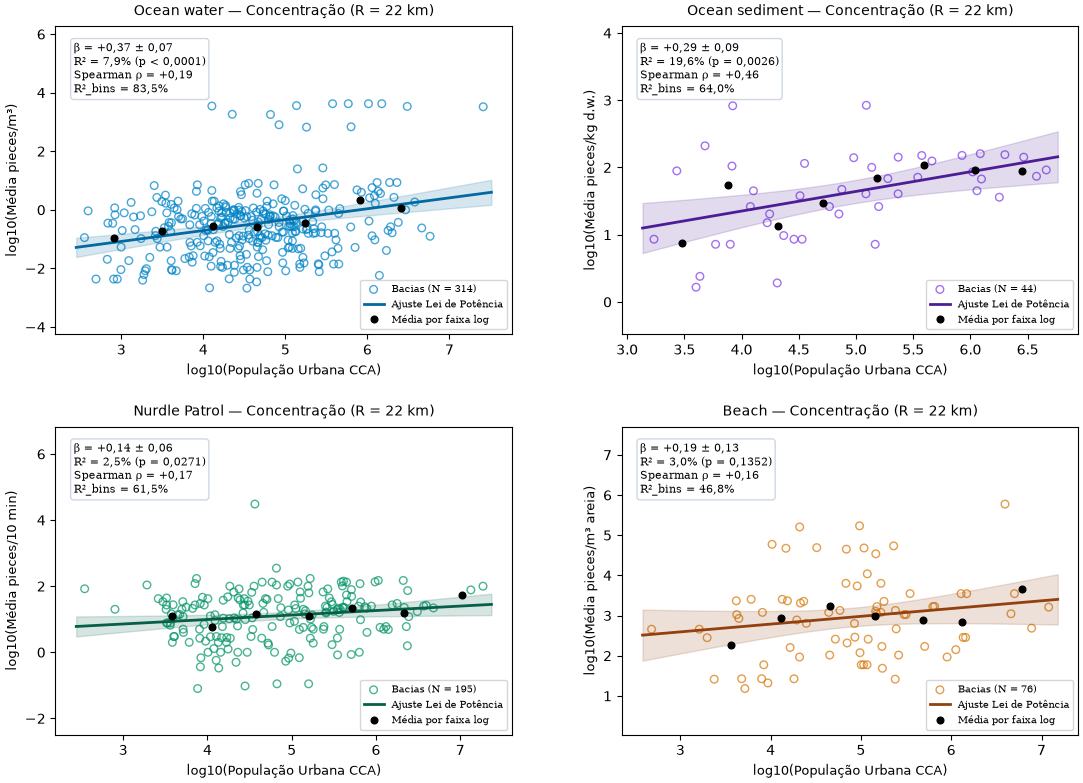

In [4]:
# 3. Grafico 2x2: Concentracao Media no Sink (R = 22 km) para cada tipo de lixo da NOAA
configs = [
    ("Ocean water", "log10(Média pieces/m³)", "#0284c7", "#0369a1"),
    ("Ocean sediment", "log10(Média pieces/kg d.w.)", "#7c3aed", "#4c1d95"),
    ("Nurdle Patrol", "log10(Média pieces/10 min)", "#059669", "#065f46"),
    ("Beach", "log10(Média pieces/m³ areia)", "#d97706", "#92400e"),
]

fig, axes = plt.subplots(2, 2, figsize=(13.2, 9.2), gridspec_kw={"wspace": 0.24, "hspace": 0.30})
for ax, (nome, ylabel, c_pt, c_ln) in zip(axes.flat, configs):
    plotar_lei_potencia(ax, pareados_r22[nome], "urban_population", "mp_mean", f"{nome} — Concentração (R = 22 km)", "log10(População Urbana CCA)", ylabel, c_pt, c_ln)

plt.show()

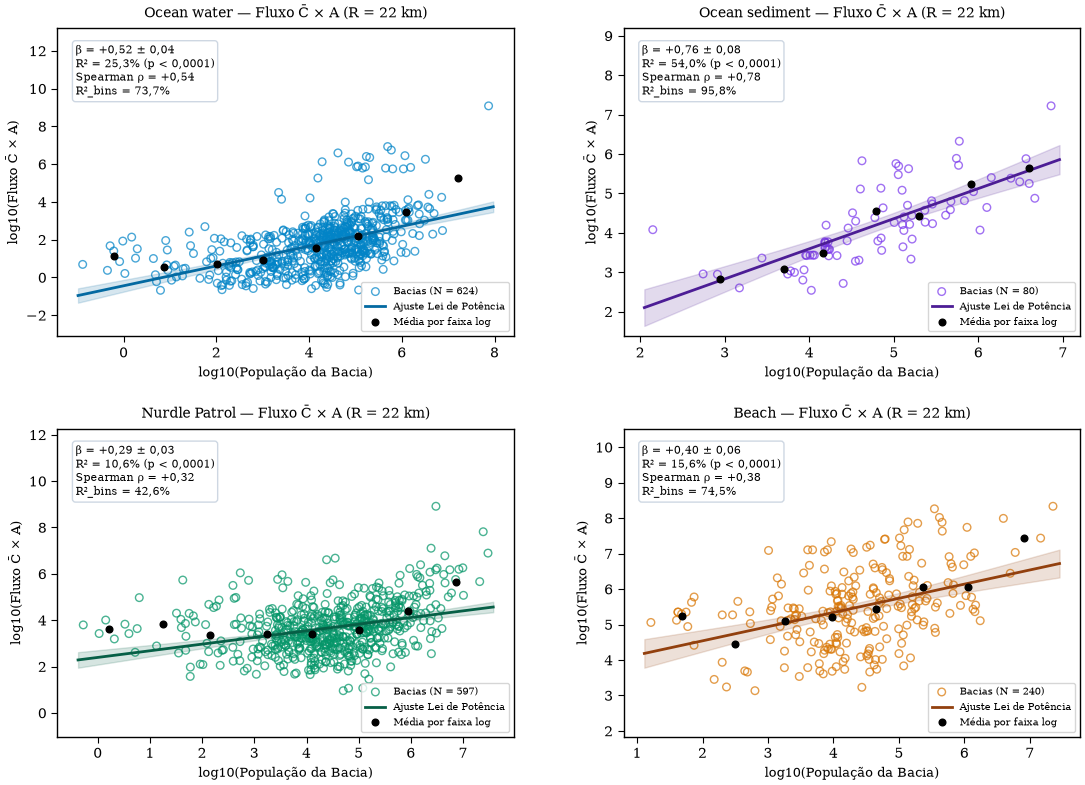

In [5]:
# 4. Grafico 2x2: Fluxo (Media x Area da Bacia, R = 22 km) para cada tipo de lixo da NOAA
fig, axes = plt.subplots(2, 2, figsize=(13.2, 9.2), gridspec_kw={"wspace": 0.24, "hspace": 0.30})
for ax, (nome, _, c_pt, c_ln) in zip(axes.flat, configs):
    plotar_lei_potencia(ax, pareados_r22[nome], "total_population", "flux", f"{nome} — Fluxo C̄ × A (R = 22 km)", "log10(População da Bacia)", "log10(Fluxo C̄ × A)", c_pt, c_ln)

plt.show()